---
## Q5. Image Binary Classification (30 pts)

**Complete this question in two separate notebooks** (see Project Requirements): `LastName_FirstName_HW3_Q5a.ipynb` for Tasks 5.1 and 5.2, and `LastName_FirstName_HW3_Q5b.ipynb` for Task 5.3. Copy the relevant task descriptions into each notebook as markdown.

**Datasets** (posted on Brightspace with this notebook):
* training set: `train_catvnoncat.h5` (209 images; keys `train_set_x`, `train_set_y`, `list_classes`)
* test set: `test_catvnoncat.h5` (50 images; keys `test_set_x`, `test_set_y`, `list_classes`)

**Place both `.h5` files in the same folder as your Q5 notebooks.** The loading code opens the files by name only, so it will fail with `FileNotFoundError` if they are stored elsewhere. Do not hard-code a full path from your own computer, since the grader must be able to run your notebook unchanged.

Each image is a $64 \times 64$ RGB image, and each label is $1$ (cat) or $0$ (non-cat). Read the files with `h5py`. Flatten each image into a vector of $64 \cdot 64 \cdot 3 = 12288$ pixel values and scale the pixel values to $[0, 1]$ by dividing by 255.

All indices you report must be **0-based**, following Python convention.


**5.3 Modified train/test split (12 pts)** *(notebook Q5b).* Discard the original test set. Using only the 209 images in `train_catvnoncat.h5`, let $d$ be the last digit of your SBU ID and define:
* new training set: the first $160 + d$ images (indices $0$ to $159 + d$);
* new test set: the remaining $49 - d$ images (indices $160 + d$ to $208$).

For example, if $d = 0$, the training set has 160 images and the test set has 49 images; if $d = 9$, they have 169 and 40 images. Print the sizes of both new sets.
* (6 pts) Retrain the model from scratch on the new training set (same preprocessing; state your hyperparameters) and print the training and test accuracies (in %, 2 decimals).
* (6 pts) Print the indices of all misclassified images in the new test set. For each, give **both** its position within the new test set and its original index in `train_catvnoncat.h5`. Display at least 4 of them as in Task 5.2.

In a short markdown cell at the end of Q5b, compare the test accuracy from 5.3 with the one from 5.1 and give one possible reason for the difference.

This code compares the predicted test labels $\hat{Y}$ with the true
labels $Y$ to find all zero-based indexes where
$\hat{y}_i \ne y_i$.

It prints the incorrect indexes and displays the first four
misclassified original RGB images, labeling each with its index, true
class, and predicted class.

In [16]:
# Import the libraries needed for data loading, arrays, and image display.
import numpy as np
import h5py
import matplotlib.pyplot as plt


# Load only the original 209-image training dataset.
with h5py.File("train_catvnoncat.h5", "r") as train_file:

    # Load the original 209 RGB images.
    all_x_orig = np.array(train_file["train_set_x"][:])

    # Load the corresponding cat/non-cat labels.
    all_y_orig = np.array(train_file["train_set_y"][:])


# d is the last digit of the SBU ID.
d = 6

# The new training set contains the first 160 + d images.
# With d = 6, this is 166 images at original indices 0 through 165.
split_index = 160 + d

# Create the new training set: original indexes 0 through 165.
new_train_x_orig = all_x_orig[:split_index]
new_train_y_orig = all_y_orig[:split_index]

# Create the new test set: original indexes 166 through 208.
new_test_x_orig = all_x_orig[split_index:]
new_test_y_orig = all_y_orig[split_index:]


These functions implement logistic regression by calculating
$\hat{Y}=\sigma(\mathbf{w}^T X+b)$, computing the binary
cross-entropy cost and its gradients $d\mathbf{w}$ and $db$, and then
updating $\mathbf{w}$ and $b$ with gradient descent.

After training, the `predict` function converts probabilities greater
than $0.5$ into class $1$ (cat) predictions and all other probabilities
into class $0$ (non-cat) predictions.

In [17]:
#classifier functions

#The sigmoid function allows us to take an input and have it mapped between 0 and 1
#This is useful because we desire to output a probability
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def initialize_parameters(dim):
    # Create a column vector of zeros:
    # one weight for each pixel feature
    w = np.zeros((dim,1))
    # Start the bias at zero
    b = 0.0
    # Return the starting parameters
    return w, b

#function for forward calculation of logistic regression
def propagate(w, b, X, Y):
    # Number of images/training examples
    m = X.shape[1]

    # Forward pass:
    # Calculate z = wᵀX + b, then turn scores into probabilities from 0 to 1
    A = sigmoid(np.dot(w.T, X) + b)

    # Avoid log(0), which would cause an error in the cost calculation
    A_safe = np.clip(A, 1e-12, 1 - 1e-12)
    # Calculate average binary cross entropy cost i.e J
    cost = -np.sum(
        Y * np.log(A_safe) + (1 - Y) * np.log(1 - A_safe)
    ) / m

    # Gradients

    # Calculate the gradient of the cost with respect to w
    # This tells us how to adjust each weight
    dw = np.dot(X, (A - Y).T) / m

    # Store both gradients in a dictionary
    db = np.sum(A - Y) / m
    # Return the gradients and one numerical cost value
    grads = {"dw": dw, "db": db}

    return grads, float(cost)
# optimize repeatedly calls propagate, then uses the gradients to update w and b.
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    # Store the cost from every iteration for the required cost plot
    costs = []

    # Repeat gradient descent for the chosen number of iterations
    for i in range(num_iterations):

        # Calculate the current cost and gradients
        grads, cost = propagate(w, b, X, Y)

        # Retrieve the gradients from the dictionary
        dw = grads["dw"]
        db = grads["db"]

        # Update the weights and bias using gradient descent
        # Move in the direction that reduces the cost
        w = w - learning_rate * dw
        b = b - learning_rate * db

        # Save this iteration's cost for plotting later
        costs.append(cost)

        # Optionally print the cost every 100 iterations
        if print_cost and i % 100 == 0:
            print(f"Cost at iteration {i}: {cost:.6f}")

    # Store the final learned parameters
    params = {"w": w, "b": b}

    # Return the final parameters, final gradients, and cost history
    return params, grads, costs

def predict(w, b, X):
    # Calculate the probability that each image is a cat
    # A has one probability for each image
    A = sigmoid(np.dot(w.T, X) + b)

    # Convert probabilities into class predictions:
    # probability > 0.5 becomes 1 (cat)
    # probability <= 0.5 becomes 0 (non-cat)
    Y_prediction = (A > 0.5).astype(int)

    # Return the predicted labels
    return Y_prediction


This code flattens and normalizes the new $166$-image training set and
$43$-image test set, then initializes a new logistic-regression model
with $\mathbf{w}=\mathbf{0}$ and $b=0$.

It retrains the model from scratch using the new training set and
reports the percentage of correct predictions on both the new training
and new test sets.

In [18]:
# Flatten each 64 x 64 x 3 image into 12,288 pixel features.
# .T gives the classifier's expected shape:
# rows = features and columns = images.
new_train_x = new_train_x_orig.reshape(
    new_train_x_orig.shape[0], -1
).T / 255.0

new_test_x = new_test_x_orig.reshape(
    new_test_x_orig.shape[0], -1
).T / 255.0

# Reshape labels into row vectors.
new_train_y = new_train_y_orig.reshape(1, -1)
new_test_y = new_test_y_orig.reshape(1, -1)


#New training-feature shape: (12288, 166)
#New training-label shape: (1, 166)
#New test-feature shape: (12288, 43)
#New test-label shape: (1, 43)


In [19]:
# adjust these
learning_rate = 0.005
num_iterations = 2000

#  fresh zero weights and a fresh zero bias.
# This ensures the model is retrained from scratch.
w, b = initialize_parameters(new_train_x.shape[0])

# Train using only the new 166-image training set.
params, grads, costs = optimize(
    w,
    b,
    new_train_x,
    new_train_y,
    num_iterations,
    learning_rate,
    print_cost=True
)

# Store the newly learned parameters.
w = params["w"]
b = params["b"]

# Predict labels for both the new training and new test sets.
new_train_predictions = predict(w, b, new_train_x)
new_test_predictions = predict(w, b, new_test_x)

# Calculate accuracies as percentages.
new_train_accuracy = np.mean(
    new_train_predictions == new_train_y
) * 100

new_test_accuracy = np.mean(
    new_test_predictions == new_test_y
) * 100

# Print the  results.
print(f"Learning rate: {learning_rate}")
print(f"Number of iterations: {num_iterations}")
print(f"New training accuracy: {new_train_accuracy:.2f}%")
print(f"New test accuracy: {new_test_accuracy:.2f}%")

Cost at iteration 0: 0.693147
Cost at iteration 100: 0.549284
Cost at iteration 200: 0.407387
Cost at iteration 300: 0.327080
Cost at iteration 400: 0.290431
Cost at iteration 500: 0.261580
Cost at iteration 600: 0.238081
Cost at iteration 700: 0.218488
Cost at iteration 800: 0.201862
Cost at iteration 900: 0.187558
Cost at iteration 1000: 0.175112
Cost at iteration 1100: 0.164178
Cost at iteration 1200: 0.154497
Cost at iteration 1300: 0.145862
Cost at iteration 1400: 0.138115
Cost at iteration 1500: 0.131124
Cost at iteration 1600: 0.124784
Cost at iteration 1700: 0.119010
Cost at iteration 1800: 0.113730
Cost at iteration 1900: 0.108883
Learning rate: 0.005
Number of iterations: 2000
New training accuracy: 100.00%
New test accuracy: 53.49%


This code compares the new test predictions with the true labels to find
each misclassified image, then reports both its position in the new test
set and its original index in `train_catvnoncat.h5`.

It displays the first four incorrect $64\times64$ RGB images in a grid,
labeling each with its new-test index, original index, true class, and
predicted class.

Misclassified images:
new test index 1, original train index 167
new test index 3, original train index 169
new test index 4, original train index 170
new test index 5, original train index 171
new test index 6, original train index 172
new test index 7, original train index 173
new test index 9, original train index 175
new test index 11, original train index 177
new test index 13, original train index 179
new test index 17, original train index 183
new test index 19, original train index 185
new test index 22, original train index 188
new test index 26, original train index 192
new test index 29, original train index 195
new test index 30, original train index 196
new test index 31, original train index 197
new test index 32, original train index 198
new test index 34, original train index 200
new test index 38, original train index 204
new test index 39, original train index 205
Total misclassified images: 20


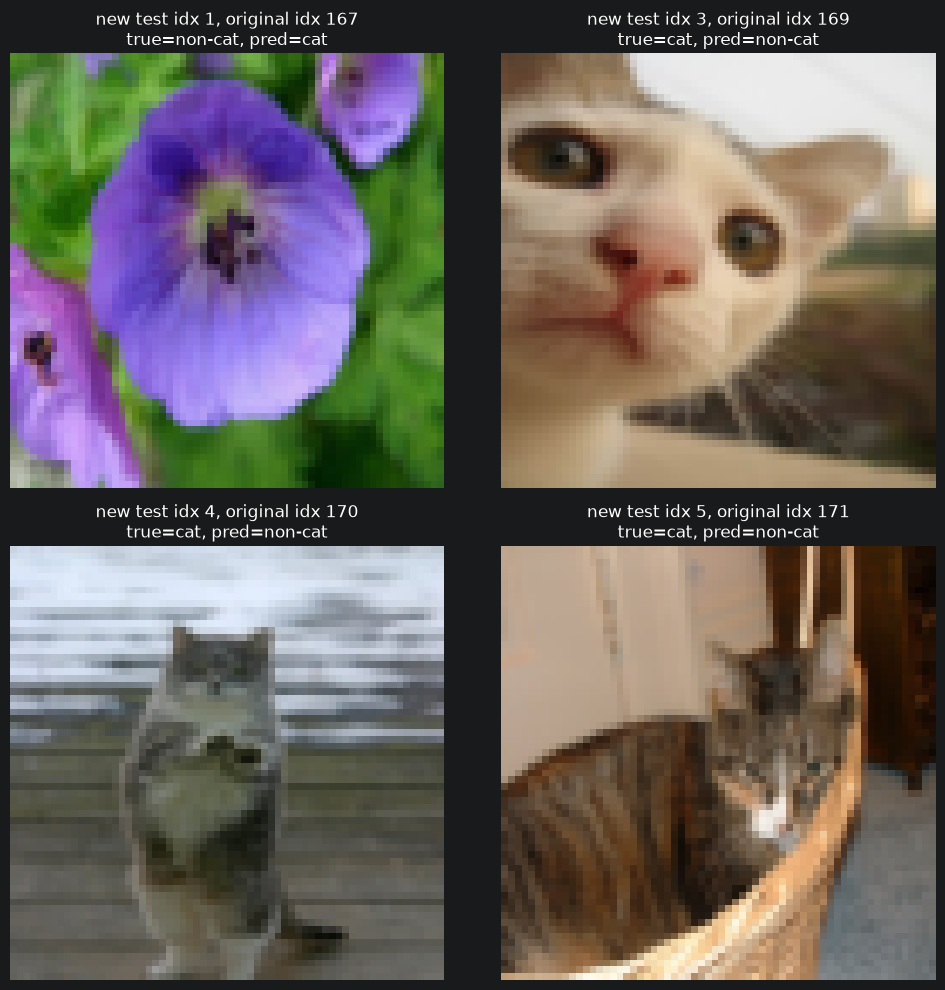

In [20]:
# Find the positions within the new test set where predictions are wrong.
incorrect = new_test_predictions.ravel() != new_test_y.ravel()
misclassified_new_test_indices = np.where(incorrect)[0]

# Print every incorrect image's local test index and original dataset index.
print("Misclassified images:")

for new_test_idx in misclassified_new_test_indices:

    # New-test position 0 corresponds to original training set index 166.
    original_train_idx = split_index + new_test_idx

    print(
        f"new test index {new_test_idx}, "
        f"original train index {original_train_idx}"
    )

# Print the total number of incorrect new test predictions.
print(f"Total misclassified images: {len(misclassified_new_test_indices)}")
# Select the first four misclassified images for display.
images_to_show = misclassified_new_test_indices[:4]

if len(images_to_show) == 0:
    print("No misclassified images were found.")

else:
    # Make a 2 by 2 image grid.
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    axes = axes.ravel()

    # Display each incorrect image.
    for ax, new_test_idx in zip(axes, images_to_show):

        # Convert the local new-test index to its original dataset index.
        original_train_idx = split_index + new_test_idx

        # Display the original unflattened 64 x 64 RGB image.
        ax.imshow(new_test_x_orig[new_test_idx])

        # Convert numeric labels to readable labels.
        true_label = (
            "cat" if new_test_y[0, new_test_idx] == 1 else "non-cat"
        )

        predicted_label = (
            "cat"
            if new_test_predictions[0, new_test_idx] == 1
            else "non-cat"
        )

        # Include both required indexes and both labels in the title.
        ax.set_title(
            f"new test idx {new_test_idx}, original idx {original_train_idx}\n"
            f"true={true_label}, pred={predicted_label}"
        )

        # Hide axis numbers around the image.
        ax.axis("off")

    # Hide unused grid spaces if fewer than four images were misclassified.
    for ax in axes[len(images_to_show):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## Comparison with Task 5.1

The test accuracy in Task 5.1 was 70.00%. The test accuracy in Task 5.3 was 53.49%, which is 16.51 percentage points lower. One possible reason is that Task 5.3 trains on fewer images (166 rather than 209) and evaluates the model on a different set of images, which may contain more difficult examples.